# Da física de uma pedra à simulação de uma missão científica

### XI SBGEA 2026 · caderno de exploração e projeto experimental

**Tudo começa com curiosidade... Aqui, começamos com uma pedra.**

Conseguimos prever onde ela vai cair? A cada resposta, uma hipótese fica visível e podemos perguntar se ela ainda serve. O caderno começa com a pedra lançada à mão e a mecânica introdutória. Na etapa de missão, a pergunta continua com **uma nova esfera instrumentada**, liberada por um foguete genérico — a pedra inicial não é lançada à mesosfera.

A contribuição científica aqui é o **simulador**: equações, integração numérica, observáveis, recuperação de parâmetros e análise de incertezas. O exemplo não propõe que estudantes construam ou lancem foguetes. Simular uma missão pode informar sua viabilidade, requisitos instrumentais e limites antes de uma campanha.

## Como usar

Execute as células em ordem. No fim, controles ipywidgets permitem escolher parâmetros e disparar uma nova simulação. O experimento é sintético: o perfil prescrito é conhecido pelo gerador para avaliação, mas o algoritmo de recuperação recebe somente medidas, geometria, modelo e priors. A comparação com a verdade acontece depois do ajuste, como em um OSSE.

As estimativas são condicionais às hipóteses. Um simulador útil torna testáveis as previsões e explícitas as limitações; uma curva convincente, por si só, não valida um modelo.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter in this project or one of its notebook folders.")
src = ROOT / "src"
sys.path.insert(0, str(src)) if str(src) not in sys.path else None

import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace
from IPython.display import display, Markdown
from sbgea_keynote.config import PHYSICS, MISSION, WIND_TRUTH, TRACKING, RETRIEVAL
from sbgea_keynote.physics.projectile import ideal_projectile, simulate_projectile
from sbgea_keynote.mission.workflow import run_fall_sphere_experiment, experiment_summary, drag_assumption_sensitivity

NAVY, BLUE, GREEN, ORANGE = "#082F73", "#2686D0", "#70AE54", "#EC8135"
plt.rcParams.update({"figure.facecolor":"white","axes.facecolor":"white","font.size":12})
print("Projeto:", ROOT)

Projeto: $KEYNOTETALK_PROJECT


## 1 · A primeira aproximação: a pedra como projétil ideal

No referencial local, com eixo vertical positivo para cima, usamos dx/dt = vx, dz/dt = vz, dvx/dt = 0 e dvz/dt = −g. A pedra tem massa pontual no modelo do movimento; a rocha desenhada no gráfico é apenas um símbolo visual. O caso ideal tem solução analítica. Compará-la com uma integração independente verifica a implementação numérica.

Alcance analítico: 65.367 m
Tempo de voo: 3.698 s
Maior erro posição numérica-analítica: 1.134e-13 m


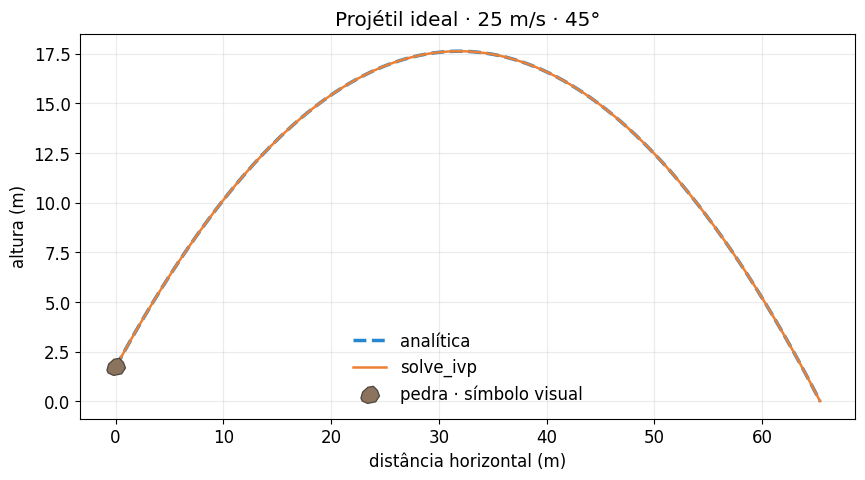

In [2]:
ideal = ideal_projectile()
numeric = simulate_projectile(drag=False, density="constant", wind="calm")
t = ideal["t"][ideal["t"] <= numeric["flight_time"]]
state = numeric["solver"].sol(t)
theta = np.deg2rad(PHYSICS.launch_angle_deg)
xa = PHYSICS.launch_speed*np.cos(theta)*t
za = PHYSICS.launch_height + PHYSICS.launch_speed*np.sin(theta)*t - .5*PHYSICS.g*t**2
err = np.max(np.hypot(state[0]-xa, state[1]-za))
print("Alcance analítico: {:.3f} m".format(ideal["range"]))
print("Tempo de voo: {:.3f} s".format(ideal["flight_time"]))
print("Maior erro posição numérica-analítica: {:.3e} m".format(err))
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(ideal["x"],ideal["y"],"--",color=BLUE,lw=2.5,label="analítica")
ax.plot(numeric["x"],numeric["y"],color=ORANGE,lw=1.8,label="solve_ivp")
from matplotlib.path import Path as MarkerPath
rock_vertices=np.array([[-1.0,-.28],[-.82,.36],[-.27,.86],[.30,.96],[.72,.54],
    [.94,-.05],[.54,-.66],[-.30,-.83],[-.86,-.58],[-1.0,-.28]])
rock_codes=[MarkerPath.MOVETO]+[MarkerPath.LINETO]*(len(rock_vertices)-2)+[MarkerPath.CLOSEPOLY]
ax.scatter([0],[PHYSICS.launch_height],marker=MarkerPath(rock_vertices,rock_codes),s=190,
    facecolor="#8C735E",edgecolor="#4D453F",lw=.9,zorder=5,label="pedra · símbolo visual")
ax.set(xlabel="distância horizontal (m)",ylabel="altura (m)",
       title="Projétil ideal · 25 m/s · 45°")
ax.grid(alpha=.25); ax.legend(frameon=False); plt.show()

## 2 · Adicionar física exige novas hipóteses

A força de arrasto quadrático é Fd = −½ρ Cd A |v − u|(v − u), relativa ao ar. A densidade, temperatura e gravidade variam com altitude na simulação mesosférica.

O perfil tabulado é uma aproximação da US Standard Atmosphere 1976 até 110 km (densidade interpolada em escala logarítmica, temperatura linear). Não representa variabilidade meteorológica ou termoesférica. O Cd é estimado por uma transição aproximada entre uma correlação de esfera em fluxo contínuo e um limite molecular livre. Nas regiões de transição, em alto Mach e fora da faixa da correlação, o arrasto é incerto; Reynolds, Knudsen e Mach são calculados para marcar essa limitação.

In [3]:
baseline = run_fall_sphere_experiment(seed=TRACKING.random_seed)
for key, value in experiment_summary(baseline).items():
    print("{}: {}".format(key, value))

apogee_km: 105.00000314245027
calibrated_thrust_kn: 38.71818921527743
release_altitude_km: 105.00000314245027
sphere_duration_s: 129.67517701774773
observations_used: 98
retrieval_rmse_m_s: 7.068652473767124
median_measurement_std_m_s: 2.0593313856638793
median_total_std_m_s: 8.260801762297671
density_scale_estimate: 0.999816657593729
useful_altitude_knots_km: [ 65.  75.  85.  95. 105.]
averaging_kernel_diagonal: [0.99880905 0.99208653 0.96542283 0.91853054 0.91289775]
reduced_chi_square: 1.1616188774888143


## 3 · Missão virtual e observações

O foguete genérico usa uma integração vertical separada: empuxo calibrado ao apogeu, massa variável durante a queima, gravidade variável e arrasto axial. Guiagem, atitude, estágios, movimento lateral e resposta ao vento foram omitidos. Não é uma missão histórica nem um projeto de veículo.

Na transição narrativa, não transformamos a pedra em carga útil: um foguete genérico leva **uma nova esfera instrumentada**. Na separação, ela herda posição e velocidade do payload, mais a velocidade de separação configurada. Sua dinâmica usa gravidade, vento neutro com altitude e arrasto relativo ao ar.

O radar observa alcance e elevação: R = √((x−xs)²+z²), ε = atan2(z,x−xs). Não mede vento nem velocidade horizontal diretamente. Cadência, ruído, covariância e perdas são configuráveis.

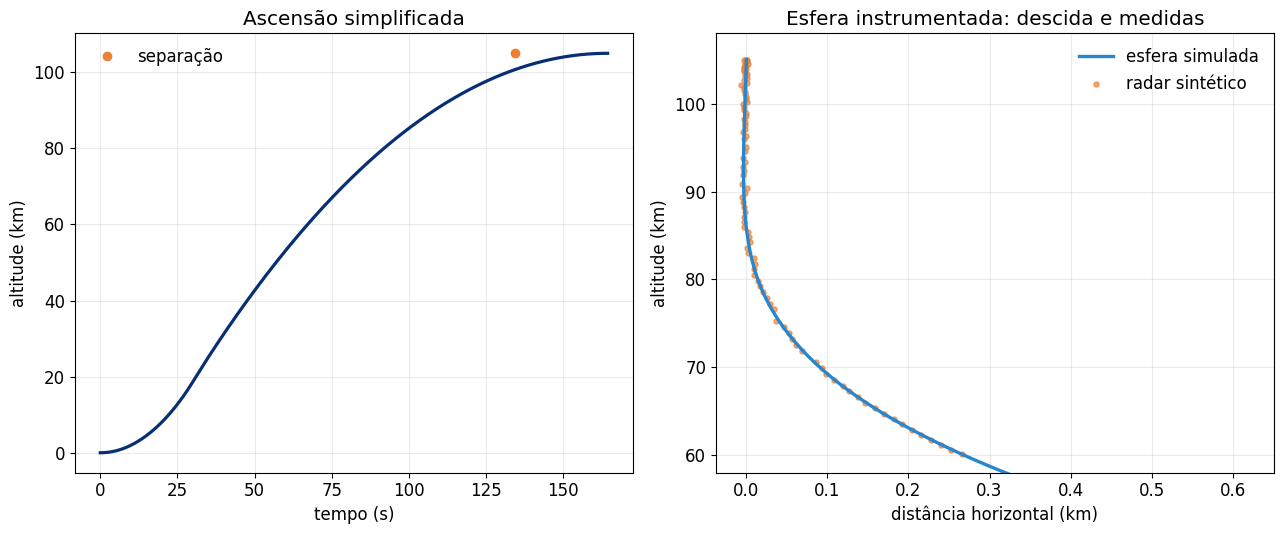

Apogeu: 105.00 km
Estado na separação [x,z,vx,vz]: [ 0.00000000e+00  1.05000003e+05  0.00000000e+00 -8.00000000e+00]
Observações válidas: 98


In [4]:
mission = baseline["mission"]
track = mission["sphere"]
obs = baseline["observations"]
fig, axs = plt.subplots(1,2,figsize=(13,5.5))
axs[0].plot(mission["rocket"]["t"],mission["rocket"]["z"]/1000,color=NAVY,lw=2.3)
axs[0].plot(mission["rocket"]["release_time_s"],mission["rocket"]["release_state"][1]/1000,
            "o",color=ORANGE,label="separação")
axs[0].set(xlabel="tempo (s)",ylabel="altitude (km)",title="Ascensão simplificada")
axs[0].grid(alpha=.25); axs[0].legend(frameon=False)
axs[1].plot(track["x"]/1000,track["z"]/1000,color=BLUE,lw=2.4,label="esfera simulada")
valid=obs["valid"][:,0]
meas=obs["measurement"][valid,0]
site=obs["station_x_m"][0]
axs[1].scatter((site+meas[:,0]*np.cos(meas[:,1]))/1000,
               (meas[:,0]*np.sin(meas[:,1]))/1000,s=13,color=ORANGE,alpha=.7,label="radar sintético")
axs[1].set(xlabel="distância horizontal (km)",ylabel="altitude (km)",
           title="Esfera instrumentada: descida e medidas",ylim=(58,108))
axs[1].grid(alpha=.25); axs[1].legend(frameon=False)
plt.tight_layout(); plt.show()
print("Apogeu: {:.2f} km".format(mission["rocket"]["apogee_m"]/1000))
print("Estado na separação [x,z,vx,vz]:", mission["sphere_initial_state"])
print("Observações válidas:",obs["n_used"])

## 4 · Recuperar o perfil de vento

A recuperação ajusta o modelo direto às medidas ponderadas pela covariância. Estima nós do vento e parâmetros auxiliares de densidade e estado de separação; priors de amplitude e curvatura regularizam o perfil. A covariância local de Gauss–Newton e o averaging kernel mostram incerteza formal e sensibilidade dos nós. Um piso de erro de modelo é apresentado separadamente.

O ajuste não recebe o perfil verdadeiro. Ele é usado apenas depois para avaliar esta realização sintética. Baixo RMSE em um OSSE não prova exatidão operacional: erros aerodinâmicos, atmosféricos, geométricos e de calibração ainda importam.

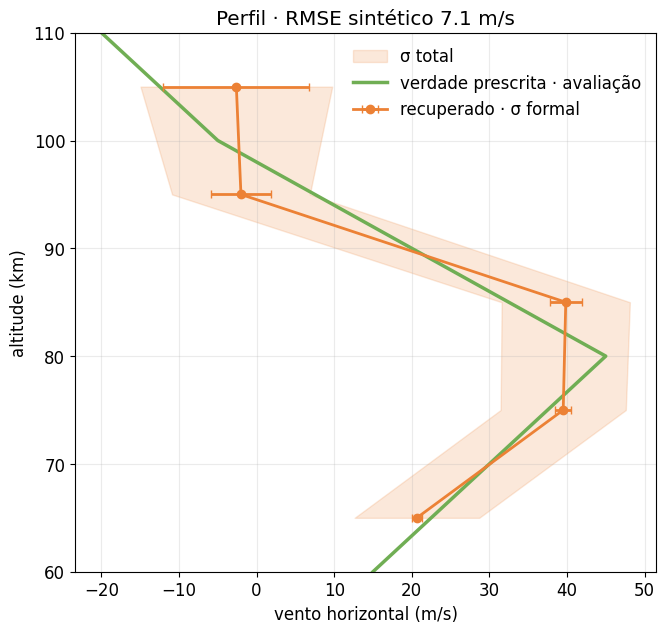

Diagonal averaging kernel: [1.   0.99 0.97 0.92 0.91]
σ formal mediana: 2.06 m/s
σ total mediana: 8.26 m/s
χ² reduzido: 1.16


In [5]:
fit=baseline["retrieval"]
score=baseline["evaluation"]
fig,ax=plt.subplots(figsize=(7.5,7))
z=fit["wind_altitude_m"]/1000
ax.fill_betweenx(z,fit["wind_m_s"]-fit["total_wind_std_m_s"],
    fit["wind_m_s"]+fit["total_wind_std_m_s"],color=ORANGE,alpha=.18,label="σ total")
ax.plot(WIND_TRUTH.speed_m_s,np.asarray(WIND_TRUTH.altitude_m)/1000,
    color=GREEN,lw=2.5,label="verdade prescrita · avaliação")
ax.errorbar(fit["wind_m_s"],z,xerr=fit["measurement_wind_std_m_s"],
    fmt="o-",color=ORANGE,lw=2,capsize=3,label="recuperado · σ formal")
ax.set(xlabel="vento horizontal (m/s)",ylabel="altitude (km)",
       title="Perfil · RMSE sintético {:.1f} m/s".format(score["rmse_m_s"]),ylim=(60,110))
ax.grid(alpha=.25); ax.legend(frameon=False); plt.show()
print("Diagonal averaging kernel:",np.round(np.diag(fit["averaging_kernel"]),2))
print("σ formal mediana: {:.2f} m/s".format(np.median(fit["measurement_wind_std_m_s"])))
print("σ total mediana: {:.2f} m/s".format(np.median(fit["total_wind_std_m_s"])))
print("χ² reduzido:",round(fit["reduced_chi_square"],2))

## 5 · Projeto experimental interativo

Os controles alteram massa e raio da esfera, Cd molecular, apogeu e separação, cadence e precisão do radar, incerteza do prior de densidade, resolução vertical e geometria de rastreio. O ajuste é disparado por botão para evitar integrações acidentais a cada movimento do controle.

A incerteza de densidade é representada pela largura do prior da escala de densidade, não por uma observação independente. A configuração de três radares é uma geometria idealizada num plano vertical. Os resultados contra a verdade prescrita são apenas métricas sintéticas; incerteza formal, resolução e sensibilidade ao arrasto são diagnósticos diferentes.

In [6]:
import ipywidgets as widgets
from IPython.display import clear_output

apogee=widgets.Dropdown(options=[90,100,105,110],value=105,description="Apogeu (km)")
release=widgets.FloatSlider(value=105,min=80,max=105,step=1,description="Separação (km)",continuous_update=False)
def _cap_release(change):
    release.max=change["new"]
    if release.value>release.max: release.value=release.max
apogee.observe(_cap_release,names="value")

mass=widgets.FloatSlider(value=.10,min=.03,max=.50,step=.01,description="Massa (kg)",continuous_update=False)
radius=widgets.FloatSlider(value=.25,min=.08,max=.40,step=.01,description="Raio (m)",continuous_update=False)
cd=widgets.FloatSlider(value=2,min=.5,max=3.5,step=.1,description="Cd molecular",continuous_update=False)
sep_v=widgets.FloatSlider(value=-8,min=-20,max=5,step=.5,description="Δv vertical (m/s)",continuous_update=False)
cadence=widgets.FloatSlider(value=1,min=.5,max=5,step=.5,description="Cadência (s)",continuous_update=False)
range_sigma=widgets.FloatSlider(value=2,min=.5,max=30,step=.5,description="σ alcance (m)",continuous_update=False)
angle_sigma=widgets.FloatLogSlider(value=.001,base=10,min=-4,max=-1.7,step=.05,description="σ elevação (°)",continuous_update=False)
density_prior=widgets.FloatSlider(value=.25,min=.05,max=.75,step=.05,description="σ prior ln(ρ)",continuous_update=False)
nknots=widgets.IntSlider(value=5,min=3,max=6,description="Nós de vento",continuous_update=False)
stations=widgets.Dropdown(options=[("1 estação",(-5000.,)),
    ("3 estações",(-8000.,0.,8000.))],value=(-5000.,),description="Geometria")
do_sensitivity=widgets.Checkbox(value=False,description="Sensibilidade a Cd ±20% (lento)")
button=widgets.Button(description="Simular configuração",button_style="primary",icon="play")
out=widgets.Output()
left=widgets.VBox([apogee,release,mass,radius,cd,sep_v])
right=widgets.VBox([cadence,range_sigma,angle_sigma,density_prior,nknots,stations,do_sensitivity])
display(widgets.HBox([left,right]),button,out)

last_design_result=None
last_design_error=None

def _run_design(_):
    global last_design_result,last_design_error
    last_design_result=None
    last_design_error=None
    with out:
        clear_output(wait=True)
        try:
            cfg=replace(MISSION,target_apogee_m=apogee.value*1000,
                release_altitude_m=release.value*1000,sphere_mass_kg=mass.value,
                sphere_radius_m=radius.value,
                sphere_free_molecular_cd=cd.value,
                sphere_release_separation_vz_m_s=sep_v.value)
            tr=replace(TRACKING,station_x_m=stations.value,cadence_s=cadence.value,
                range_sigma_m=range_sigma.value,elevation_sigma_deg=angle_sigma.value,random_seed=2026)
            knots=np.linspace(65_000,min(105_000,release.value*1000-1_000),nknots.value)
            rc=replace(RETRIEVAL,wind_knot_altitudes_m=tuple(knots),
                log_density_prior_sigma=density_prior.value)
            result=run_fall_sphere_experiment(cfg,tr,rc,seed=2026)
            last_design_result=result
            f,e=result["retrieval"],result["evaluation"]
            useful=f["wind_altitude_m"][f["total_wind_std_m_s"]<15]/1000
            display(Markdown("**RMSE sintético:** {:.2f} m/s · **σ medição mediana:** {:.2f} m/s · **σ total mediana:** {:.2f} m/s".format(
                e["rmse_m_s"],np.median(f["measurement_wind_std_m_s"]),np.median(f["total_wind_std_m_s"]))))
            display(Markdown("**χ² reduzido:** {:.2f} · **escala de densidade:** {:.3f} ± {:.3f} · **observações:** {}".format(
                f["reduced_chi_square"],f["density_scale"],f["density_scale_std"],result["observations"]["n_used"])))
            bulk_density=mass.value/(4*np.pi*radius.value**3/3)
            display(Markdown("Esfera equivalente: massa {:.3f} kg, raio {:.2f} m, densidade média {:.2f} kg/m³.".format(
                mass.value,radius.value,bulk_density)))
            display(Markdown("Diagonal do averaging kernel: " + np.array2string(np.diag(f["averaging_kernel"]),precision=2)))
            display(Markdown("Altitudes com σ total < 15 m/s: {}.".format(
                "{:.0f}–{:.0f} km".format(useful.min(),useful.max()) if useful.size else "nenhuma")))
            fig,ax=plt.subplots(figsize=(7,6))
            z=f["wind_altitude_m"]/1000
            ax.fill_betweenx(z,f["wind_m_s"]-f["total_wind_std_m_s"],
                f["wind_m_s"]+f["total_wind_std_m_s"],color=ORANGE,alpha=.18,label="σ total")
            ax.plot(WIND_TRUTH.speed_m_s,np.asarray(WIND_TRUTH.altitude_m)/1000,
                color=GREEN,lw=2.3,label="verdade · avaliação sintética")
            ax.errorbar(f["wind_m_s"],z,xerr=f["measurement_wind_std_m_s"],
                fmt="o-",color=ORANGE,capsize=3,label="recuperado")
            ax.set(xlabel="vento horizontal (m/s)",ylabel="altitude (km)",ylim=(60,110))
            ax.grid(alpha=.25);ax.legend(frameon=False);plt.show()
            if do_sensitivity.value:
                sens=drag_assumption_sensitivity(result,cfg,tr,rc,fractional_change=.20)
                display(Markdown("Meia diferença para Cd molecular ±20%: mediana de {:.2f} m/s nos nós; sensibilidade de hipótese, separada do ruído.".format(
                    np.median(sens["wind_half_spread_m_s"]))))
        except Exception as exc:
            last_design_error=repr(exc)
            display(Markdown("**Configuração não concluída:** {}".format(exc)))
button.on_click(_run_design)

Button(button_style='primary', description='Simular configuração', icon='play', style=ButtonStyle())

Output()

## 6 · O simulador como capacidade científica

A cadeia é **modelo físico → experimento virtual → observações simuladas → recuperação de parâmetros → avaliação de incertezas → otimização do experimento → novo modelo**. Ela permite avaliar viabilidade, parâmetros observáveis, precisão necessária, limites de altitude e as incertezas dominantes antes de uma campanha.

**Da física básica à concepção de uma missão científica: o conhecimento que permite planejar o experimento é tão importante quanto a capacidade de realizá-lo.**

Uma demonstração independente de outro instrumento — o interferômetro Fabry–Pérot — está no caderno FabryPerot.ipynb.